Text(0.5, 1.0, 'scatter plot')

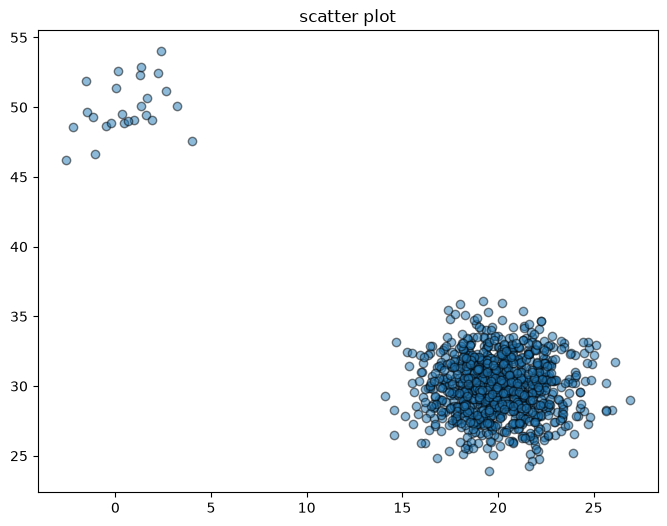

In [2]:
import pandas as pd
import numpy as np
x = pd.DataFrame({
    'x1': np.concatenate([np.random.normal(20,2,1000),np.random.normal(1,2,25)]),
    # majority center at 20 and outliers center at 1
    # x1 is column1 of the df, concatenating 1000 numbers and 25 numbers 
    # concatenate: stacking arrays end to end (row-wise)
    # np.random.normal(loc,scale,size): 
    # loc:mean of distribution 
    # scale:standard deviation(std) how tightly clustered
    # size:num of samples
    'x2':np.concatenate([np.random.normal(30,2,1000),np.random.normal(50,2,25)]),
    # x2 is column2 of the df 
    # df.shape: (1025,2)
})
x.shape
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(
    x['x1'],x['x2'],alpha=0.5,edgecolors='k'
)
plt.title('scatter plot')


<Axes: ylabel='Density'>

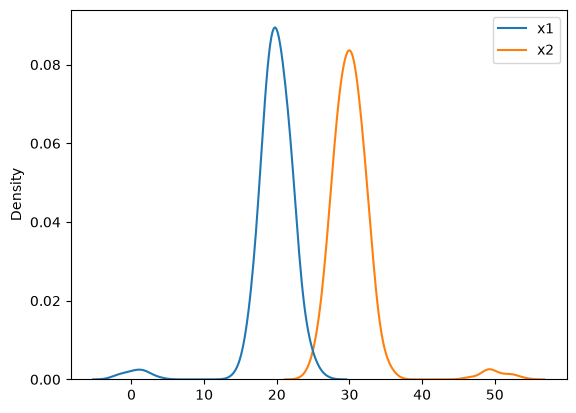

In [11]:
import seaborn as sns
# kde: kernel density estimation: visualizing distribution 
sns.kdeplot(x)

(1025, 2)


Text(0.5, 0, 'interqquartile')

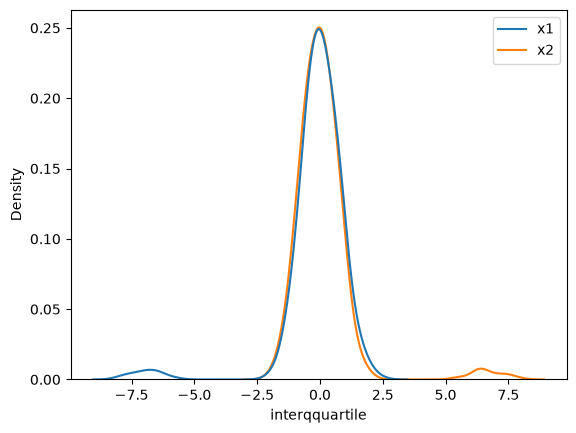

In [ ]:
from sklearn import preprocessing
# blind to extreme outliers at the tails
# used in financial transaction, sensor logs and anomaly detection 
scaler=preprocessing.RobustScaler()
robust=scaler.fit_transform(x)
robust_df=pd.DataFrame(robust,columns=['x1','x2'])
print(f'{robust_df.shape}')
sns.kdeplot(robust_df)
plt.xlabel("interqquartile")
# total area under the curve must equal 1 for kde(kernel density estimation plot)

Text(0.5, 0, 'Z scores')

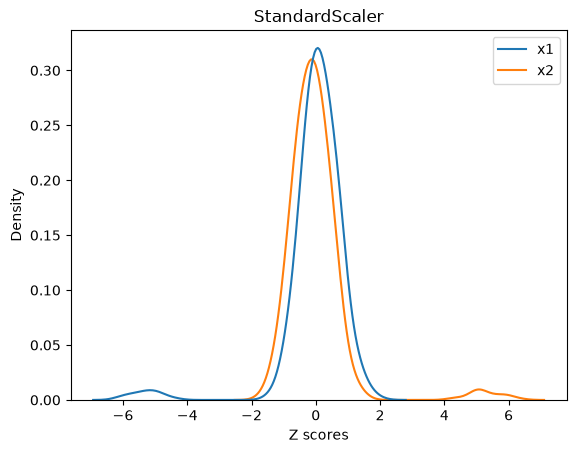

In [27]:
scaler=preprocessing.StandardScaler()
# 0 mean and 1 std 
# for algorithms assumes normal distribution, like linear regression, logistic regression and SVM 
standard=scaler.fit_transform(x)
# strip from the df structure during fit_transform process 
standard_df=pd.DataFrame(standard,columns=['x1','x2'])
ax2=sns.kdeplot(standard_df)
ax2.set_title('StandardScaler')
ax2.set_xlabel("Z scores")

Text(0.5, 0, '0 absolute min and 1 absolute max')

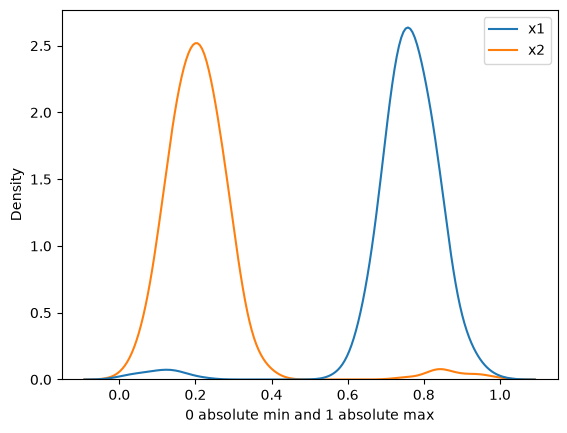

In [28]:
scaler=preprocessing.MinMaxScaler()
# for neural networks and image pixel values
# drawback: highly sensitive to outliers, which can crush normal data into tiny corner.
minmax=scaler.fit_transform(x)
minmax_df=pd.DataFrame(minmax,columns=['x1','x2'])
sns.kdeplot(minmax_df)
plt.xlabel('0 absolute min and 1 absolute max')